# 01 — Exploratory Data Analysis: AI4I 2020 Predictive Maintenance

**Goal of this notebook:** verify the dataset facts *against the real data* before any modelling
(shape, dtypes, nulls, exact column names, class balance), understand how the failure modes relate
to the target, and look at how the process parameters differ between failing and healthy runs.

All figures are written to `reports/figures/` at 300 dpi.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

from src.config import (DATA_CSV, FAILURE_MODES, FAILURE_MODE_NAMES, NUM_COLS, PRETTY,
                        TARGET, TYPE_ORDER)
from src.data import load_raw, get_X_y
from src import plots
from src.plots import CLASS_COLORS, CLASS_LABELS, C_FAIL, INK_2, savefig

plots.set_style()
pd.set_option("display.width", 140)

## 1. Raw schema — exact column names as delivered by the source

In [2]:
raw = pd.read_csv(DATA_CSV)          # cached copy of fetch_ucirepo(id=601).data.original
print("shape:", raw.shape)
print("columns:", list(raw.columns))
pd.DataFrame({"dtype": raw.dtypes.astype(str), "nulls": raw.isna().sum(), "n_unique": raw.nunique()})

shape: (10000, 14)
columns: ['UID', 'Product ID', 'Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


,dtype,nulls,n_unique
UID,int64,0,10000
Product ID,str,0,10000
Type,str,0,3
Air temperature,float64,0,93
Process temperature,float64,0,82
Rotational speed,int64,0,941
Torque,float64,0,577
Tool wear,int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


**Flag vs. the brief:** the `ucimlrepo` copy names the columns *without* unit suffixes
(`Air temperature`, not `Air temperature [K]`). The original UCI CSV uses the bracketed names and `UDI`
instead of `UID`. `src/data.py` normalises both conventions to snake_case names, so the rest of the
project is independent of the source.

In [3]:
df = load_raw()
print("normalised columns:", list(df.columns))
print("duplicate rows (ignoring IDs):", df.drop(columns=["uid", "product_id"]).duplicated().sum())
print("uid unique:", df.uid.is_unique, "| product_id unique:", df.product_id.is_unique)
print("product_id prefix == type for every row:", (df.product_id.str[0] == df.type).all())
df.describe().T.round(2)

normalised columns: ['uid', 'product_id', 'type', 'air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
duplicate rows (ignoring IDs): 0
uid unique: True | product_id unique: True
product_id prefix == type for every row: True


,count,mean,std,min,25%,50%,75%,max
uid,10000.0,5000.50,2886.90,1.0,2500.75,5000.5,7500.25,10000.0
air_temp_k,10000.0,300.00,2.00,295.3,298.30,300.1,301.50,304.5
process_temp_k,10000.0,310.01,1.48,305.7,308.80,310.1,311.10,313.8
rot_speed_rpm,10000.0,1538.78,179.28,1168.0,1423.00,1503.0,1612.00,2886.0
torque_nm,10000.0,39.99,9.97,3.8,33.20,40.1,46.80,76.6
tool_wear_min,10000.0,107.95,63.65,0.0,53.00,108.0,162.00,253.0
machine_failure,10000.0,0.03,0.18,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00,0.07,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01,0.11,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.01,0.10,0.0,0.00,0.0,0.00,1.0


## 2. Class balance

machine_failure
0    9661
1     339
positive rate = 339/10000 = 3.39%
imbalance ratio (neg:pos) = 28.50 : 1
a classifier that always predicts 'no failure' gets accuracy = 96.61%  <- why accuracy is misleading


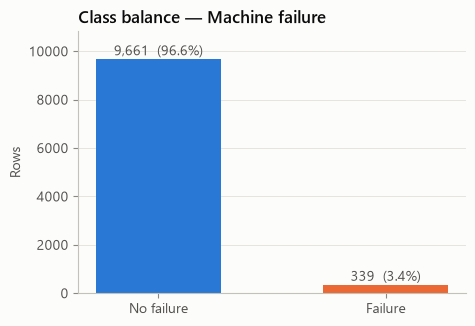

In [4]:
counts = df[TARGET].value_counts().sort_index()
pos_rate = df[TARGET].mean()
print(counts.to_string())
print(f"positive rate = {counts[1]}/{len(df)} = {pos_rate:.2%}")
print(f"imbalance ratio (neg:pos) = {counts[0]/counts[1]:.2f} : 1")
print(f"a classifier that always predicts 'no failure' gets accuracy = {1-pos_rate:.2%}  <- why accuracy is misleading")

fig, ax = plt.subplots(figsize=(5, 3.4))
bars = ax.bar([CLASS_LABELS[k] for k in counts.index], counts.values,
              color=[CLASS_COLORS[k] for k in counts.index], width=0.55)
for b, n in zip(bars, counts.values):
    ax.annotate(f"{n:,}  ({n/len(df):.1%})", (b.get_x() + b.get_width()/2, n),
                xytext=(0, 3), textcoords="offset points", ha="center", color=INK_2)
ax.set_ylabel("Rows"); ax.set_title("Class balance — Machine failure")
ax.grid(axis="x", visible=False); ax.margins(y=0.12)
savefig(fig, "01_class_balance"); plt.show()

## 3. How does the target relate to the five failure-mode flags?

The brief describes `Machine failure` as the OR of `TWF/HDF/PWF/OSF/RNF`. Check it rather than assume it.

In [5]:
any_mode = df[FAILURE_MODES].max(axis=1)
print(pd.crosstab(df[TARGET], any_mode, rownames=["machine_failure"], colnames=["any mode flag"]))

flag_no_fail = df[(df[TARGET] == 0) & (any_mode == 1)]
fail_no_flag = df[(df[TARGET] == 1) & (any_mode == 0)]
print(f"\nflag set but machine_failure=0 : {len(flag_no_fail)}  -> modes:", flag_no_fail[FAILURE_MODES].sum().to_dict())
print(f"machine_failure=1 but no flag : {len(fail_no_flag)}")
print(f"RNF rows total = {df.RNF.sum()}, of which machine_failure=1: {(df.RNF & df[TARGET]).sum()}")

# How strong is the leak? Using "any flag" as a predictor, no model needed:
tp = ((any_mode == 1) & (df[TARGET] == 1)).sum()
print(f"\n'any flag' as a predictor -> recall {tp/df[TARGET].sum():.1%}, precision {tp/any_mode.sum():.1%}")

any mode flag       0    1
machine_failure           
0                9643   18
1                   9  330

flag set but machine_failure=0 : 18  -> modes: {'TWF': 0, 'HDF': 0, 'PWF': 0, 'OSF': 0, 'RNF': 18}
machine_failure=1 but no flag : 9
RNF rows total = 19, of which machine_failure=1: 1

'any flag' as a predictor -> recall 97.3%, precision 94.8%


**Findings**
- The OR relation holds for 9,973 / 10,000 rows but **not exactly**: 18 rows have `RNF=1` with
  `machine_failure=0` (only 1 of 19 RNF events is labelled as a failure), and 9 failures have **no** mode flag.
  These are known quirks of this synthetic dataset.
- **Decision:** keep `machine_failure` as given (it is the defined target); do not relabel.
- Even this imperfect OR predicts the target at ~97% recall / ~95% precision with zero learning — which is
  exactly why the flags are **leakage** and must be dropped from X (done in `src/data.get_X_y`).

## 4. Failure-mode breakdown

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19

rows by number of simultaneous modes: {0: 9652, 1: 324, 2: 23, 3: 1}


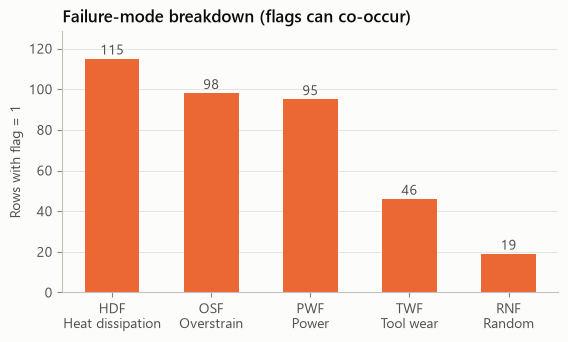

In [6]:
mode_counts = df[FAILURE_MODES].sum().sort_values(ascending=False)
n_modes = df[FAILURE_MODES].sum(axis=1)
print(mode_counts.to_string())
print("\nrows by number of simultaneous modes:", n_modes.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(figsize=(6.4, 3.4))
labels = [f"{m}\n{FAILURE_MODE_NAMES[m].replace(' failure', '')}" for m in mode_counts.index]
bars = ax.bar(labels, mode_counts.values, color=C_FAIL, width=0.55)
for b, n in zip(bars, mode_counts.values):
    ax.annotate(str(n), (b.get_x() + b.get_width()/2, n), xytext=(0, 3),
                textcoords="offset points", ha="center", color=INK_2)
ax.set_ylabel("Rows with flag = 1")
ax.set_title("Failure-mode breakdown (flags can co-occur)")
ax.grid(axis="x", visible=False); ax.margins(y=0.12)
savefig(fig, "02_failure_mode_breakdown"); plt.show()

## 5. Feature distributions, failure vs. no failure

With only 3.4% positives, raw-count histograms would make the failure class invisible, so each class is
normalised to its own density — we compare **shapes**, not counts.

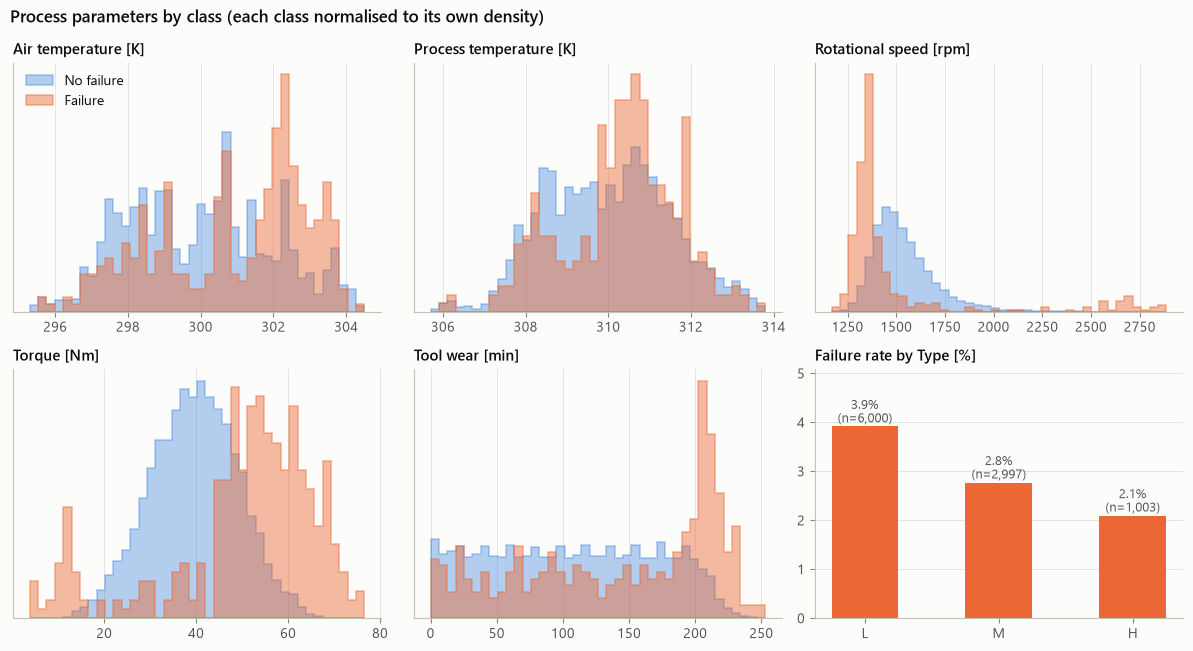

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.6))
for ax, col in zip(axes.flat, NUM_COLS):
    bins = np.histogram_bin_edges(df[col], bins=40)
    for k in (0, 1):
        ax.hist(df.loc[df[TARGET] == k, col], bins=bins, density=True, histtype="stepfilled",
                alpha=0.35 if k == 0 else 0.45, color=CLASS_COLORS[k], edgecolor=CLASS_COLORS[k],
                linewidth=1.2, label=CLASS_LABELS[k])
    ax.set_title(PRETTY[col], fontsize=10.5); ax.set_yticks([])

# 6th panel: failure rate by product Type (justifies the ordinal L<M<H encoding)
ax = axes.flat[5]
rate = df.groupby("type")[TARGET].mean().reindex(TYPE_ORDER)
n = df.type.value_counts().reindex(TYPE_ORDER)
bars = ax.bar(rate.index, rate.values * 100, color=C_FAIL, width=0.5)
for b, r, k in zip(bars, rate.values, n.values):
    ax.annotate(f"{r:.1%}\n(n={k:,})", (b.get_x() + b.get_width()/2, r*100), xytext=(0, 3),
                textcoords="offset points", ha="center", color=INK_2, fontsize=9)
ax.set_title("Failure rate by Type [%]", fontsize=10.5); ax.margins(y=0.3); ax.grid(axis="x", visible=False)

axes.flat[0].legend(loc="upper left")
fig.suptitle("Process parameters by class (each class normalised to its own density)",
             x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
savefig(fig, "03_feature_distributions"); plt.show()

In [8]:
# Numeric view of the same thing: medians by class and a rank-based effect size
rows = []
for col in NUM_COLS:
    a, b = df.loc[df[TARGET] == 0, col], df.loc[df[TARGET] == 1, col]
    u, p = mannwhitneyu(a, b)
    rows.append({"feature": col, "median_no_fail": a.median(), "median_fail": b.median(),
                 "AUC_single_feature": u / (len(a) * len(b)), "p_value": p})
pd.DataFrame(rows).set_index("feature").round(4)

,median_no_fail,median_fail,AUC_single_feature,p_value
feature,,,,
air_temp_k,300.0,301.6,0.3673,0.0000
process_temp_k,310.0,310.4,0.4363,0.0001
rot_speed_rpm,1507.0,1365.0,0.7667,0.0000
torque_nm,39.9,53.7,0.2298,0.0000
tool_wear_min,107.0,165.0,0.3379,0.0000


`AUC_single_feature` = P(value in a healthy run > value in a failing run); 0.5 means no separation;
the further from 0.5 (in either direction) the more that feature alone separates the classes.

## 6. Torque vs. rotational speed

These are the two main controllable parameters and they are strongly anti-correlated by construction.

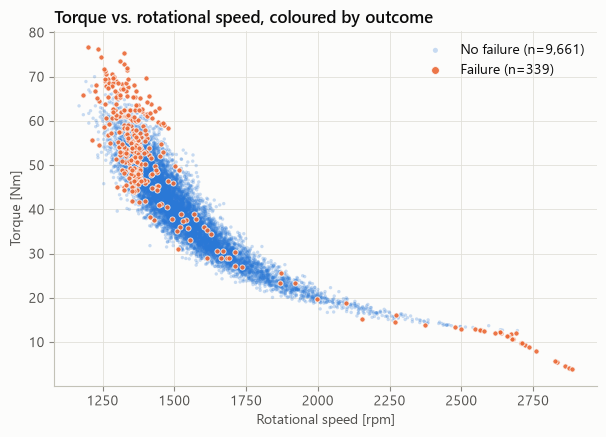

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for k, s, a in ((0, 6, 0.25), (1, 14, 0.9)):
    d = df[df[TARGET] == k]
    ax.scatter(d.rot_speed_rpm, d.torque_nm, s=s, alpha=a, color=CLASS_COLORS[k],
               edgecolor=plots.SURFACE if k else "none", linewidth=0.6,
               label=f"{CLASS_LABELS[k]} (n={len(d):,})")
ax.set_xlabel(PRETTY["rot_speed_rpm"]); ax.set_ylabel(PRETTY["torque_nm"])
ax.set_title("Torque vs. rotational speed, coloured by outcome")
ax.legend(loc="upper right", markerscale=1.5)
savefig(fig, "04_torque_vs_speed"); plt.show()

## 7. Correlation heatmap (Spearman — robust to the right-skewed rpm distribution)

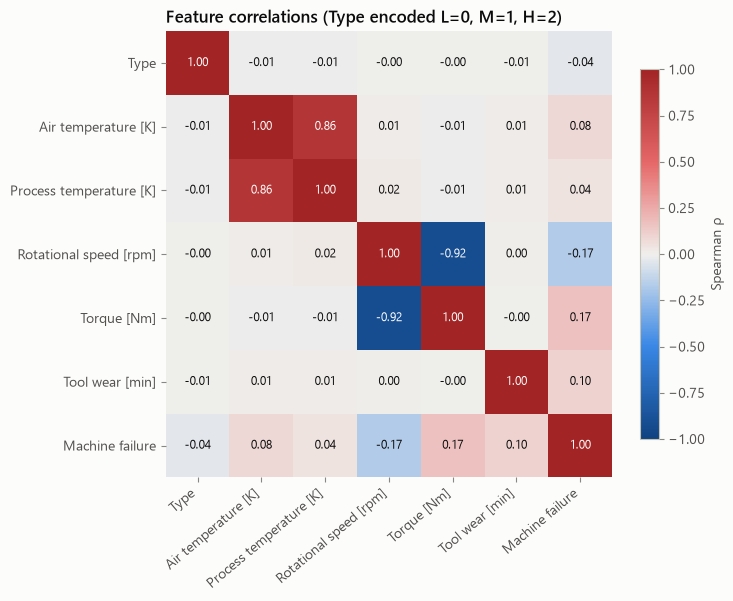

torque_nm         0.169
rot_speed_rpm    -0.167
tool_wear_min     0.102
air_temp_k        0.083
process_temp_k    0.040
type             -0.037
Name: machine_failure, dtype: float64

In [10]:
corr_df = df[NUM_COLS + [TARGET]].assign(type=df.type.map({t: i for i, t in enumerate(TYPE_ORDER)}))
corr_df = corr_df[["type"] + NUM_COLS + [TARGET]]
corr = corr_df.corr(method="spearman")
labels = [PRETTY[c] for c in corr.columns]

fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(corr.values, cmap=plots.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right"); ax.set_yticks(range(len(labels)), labels)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(v) > 0.6 else plots.INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Feature correlations (Type encoded L=0, M=1, H=2)")
for s in ax.spines.values(): s.set_visible(False)
savefig(fig, "05_correlation_heatmap"); plt.show()
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

## 8. The modelling matrix — leakage columns removed

In [11]:
X, y = get_X_y(df)
print("X columns:", list(X.columns))
print("X shape:", X.shape, "| y positives:", int(y.sum()), f"({y.mean():.2%})")
dropped = sorted(set(df.columns) - set(X.columns) - {TARGET})
print("dropped from X:", dropped)
assert not set(FAILURE_MODES) & set(X.columns)

X columns: ['type', 'air_temp_k', 'process_temp_k', 'rot_speed_rpm', 'torque_nm', 'tool_wear_min']
X shape: (10000, 6) | y positives: 339 (3.39%)
dropped from X: ['HDF', 'OSF', 'PWF', 'RNF', 'TWF', 'product_id', 'uid']


## 9. Summary — what the data showed

| Fact | Brief said | Real data |
|---|---|---|
| Shape | 10,000 rows | **10,000 × 14** ✔ |
| Missing values | none | **0** ✔; also 0 duplicate rows |
| Column names | `Air temperature [K]`, … | **no unit suffixes** in the `ucimlrepo` copy (`Air temperature`, …) → normalised in `src/data.py` |
| Positive rate | ≈ 3.4 % | **339 / 10,000 = 3.39 %**, imbalance **28.50 : 1** |
| Target = OR of modes | "essentially" | true for 9,973 rows; **18** RNF rows have `machine_failure=0`, **9** failures have no flag. Target kept as-is |
| `Type` ordinal L<M<H | — | failure rate is monotone **L 3.9 % > M 2.8 % > H 2.1 %**, so the ordinal encoding is consistent with the data |

**Leakage check:** the mode flags alone (simple OR, no model) give 97.3 % recall / 94.8 % precision, so they are
outcomes, not inputs. X has 6 columns: `type` plus the 5 process parameters. `TWF, HDF, PWF, OSF, RNF, uid, product_id`
are dropped (asserted in code).

**Signal:**
- Failures run at **higher torque** (median 53.7 vs 39.9 Nm), **lower rpm** (1365 vs 1507), **higher tool wear**
  (165 vs 107 min, with a sharp spike at ~200–240 min, matching the TWF window) and **higher air temperature**.
- Failures sit at **both ends** of the torque/rpm band: high torque at low rpm, and also very low torque at high rpm.
  That fits PWF, which fires when power is either too high or too low, so risk is **U-shaped in power**.
- Linear correlations with the target are weak (|ρ| ≤ 0.17) even though the class distributions are clearly
  different. The relationships are non-linear and threshold-like, so tree ensembles should beat logistic
  regression. The physics features (power, temp diff, overstrain) give a linear model a chance to capture them.
- Air and process temperature are strongly collinear (ρ = 0.86), and so are rpm and torque (ρ = −0.92). This matters
  when reading linear-model coefficients and SHAP attributions.
- Baseline to beat: "always no failure" scores **96.6 % accuracy** and catches zero failures. That is why accuracy
  is never used to select a model.
